# HeatMatch Similarity in creapy

Pairwise HeatMatch similarity (Long et al. 2026, DOI: 10.1145/3803539) between all subjects viewing one stimulus.
Two scores per subject pair:

- **`s_loc`**: locational similarity: do the two subjects saccade *in the same places*?
- **`s_dir`**: directional similarity: do their saccades *point the same way* where they overlap?

Both in [0, 1]. Computation is delegated to the `heatmatch` package; creapy adds the per-subject
orientation fields, the pairwise loop and the result visualizations.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

import creapy
from creapy.gaze.saccade import SaccadeData

## Load a stimulus
The synthetic example dataset (twelve invented viewers on two drawn pictures) stands in for a fixation report:
fixation table, inferred saccades, `SaccadeData`. Replace the path with your own EyeLink or Tobii export.

In [2]:
import os
from creapy.examples import example_folder

folder = example_folder()
df, fix_mapping = creapy.load_fixations(os.path.join(folder, 'demo_fixations.csv'))
stim_name, df_fixations = list(df.groupby(fix_mapping['stim_col']))[0]
df_saccades, sac_mapping = creapy.fixations_to_saccades(df_fixations, fix_mapping)
ds = SaccadeData(df_saccades, os.path.join(folder, stim_name), **sac_mapping)
ds.subj_index.nunique(), len(ds.df)

(12, 1049)

## Compute pairwise similarities
`sigma` is the kernel bandwidth of the orientation fields (px).
`density_coherence_tradeoff` ∈ [0, 1] controls how `s_dir` weights grid points
(1 = density only → statistically redundant with `s_loc`; recommended ~0.5).
Fields are cached per sigma, so recomputing with a different tradeoff is cheap.

In [3]:
res = ds.compute_heatmatch_similarity(sigma=50, density_coherence_tradeoff=0.5)
res.df_sim.head()

Computing pairwise similarities: 100%|██████████| 78/78 [00:00<00:00, 1290.86it/s]


,subject_a,subject_b,s_loc,s_dir
0,P01,P01,1.000000,1.000000
1,P01,P02,0.944927,0.760490
2,P01,P03,0.897497,0.768623
3,P01,P04,0.946890,0.756689
4,P01,P05,0.925658,0.804173


## Similarity matrix

In [4]:
res.matrix(which='s_dir').round(2)

subject_b,P01,P02,P03,P04,P05,P06,P07,P08,P09,P10,P11,P12
subject_a,,,,,,,,,,,,
P01,1.00,0.76,0.77,0.76,0.80,0.79,0.67,0.76,0.74,0.72,0.76,0.68
P02,0.76,1.00,0.76,0.76,0.81,0.75,0.71,0.78,0.72,0.76,0.73,0.67
P03,0.77,0.76,1.00,0.77,0.74,0.75,0.75,0.72,0.74,0.75,0.72,0.65
P04,0.76,0.76,0.77,1.00,0.75,0.72,0.66,0.70,0.71,0.69,0.73,0.64
P05,0.80,0.81,0.74,0.75,1.00,0.81,0.75,0.80,0.78,0.76,0.77,0.70
P06,0.79,0.75,0.75,0.72,0.81,1.00,0.72,0.77,0.76,0.69,0.74,0.73
P07,0.67,0.71,0.75,0.66,0.75,0.72,1.00,0.74,0.80,0.76,0.74,0.72
P08,0.76,0.78,0.72,0.70,0.80,0.77,0.74,1.00,0.81,0.78,0.79,0.77
P09,0.74,0.72,0.74,0.71,0.78,0.76,0.80,0.81,1.00,0.78,0.82,0.82


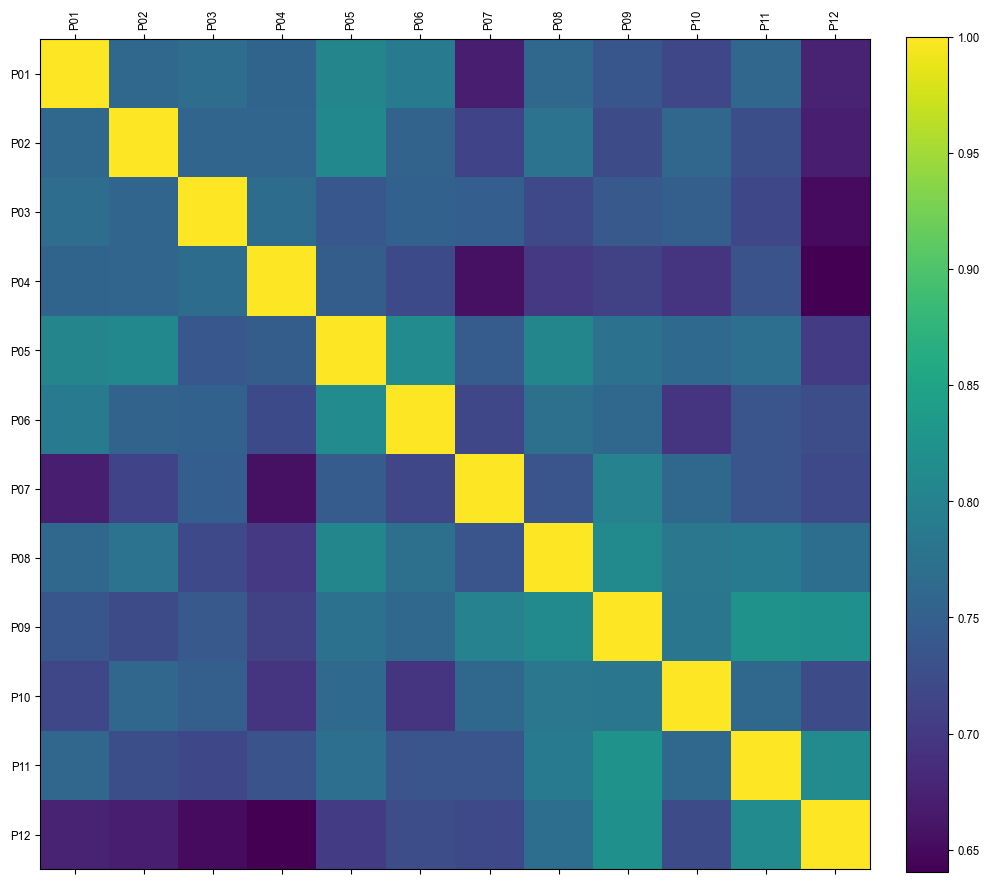

subject_b,P01,P02,P03,P04,P05,P06,P07,P08,P09,P10,P11,P12
subject_a,,,,,,,,,,,,
P01,1.000000,0.760490,0.768623,0.756689,0.804173,0.789763,0.670687,0.759968,0.736131,0.717451,0.759609,0.676586
P02,0.760490,1.000000,0.758350,0.757409,0.808573,0.754998,0.712181,0.777491,0.724647,0.758701,0.726675,0.670536
P03,0.768623,0.758350,1.000000,0.767617,0.738602,0.751979,0.748321,0.720160,0.740313,0.749788,0.717735,0.651446
P04,0.756689,0.757409,0.767617,1.000000,0.746956,0.721232,0.657008,0.700318,0.711446,0.694012,0.732312,0.640447
P05,0.804173,0.808573,0.738602,0.746956,1.000000,0.813828,0.745591,0.804986,0.775699,0.763183,0.771978,0.703924
P06,0.789763,0.754998,0.751979,0.721232,0.813828,1.000000,0.717503,0.773603,0.760029,0.694587,0.735483,0.725321
P07,0.670687,0.712181,0.748321,0.657008,0.745591,0.717503,1.000000,0.735323,0.800012,0.760777,0.735860,0.719296
P08,0.759968,0.777491,0.720160,0.700318,0.804986,0.773603,0.735323,1.000000,0.812366,0.783563,0.787776,0.769880
P09,0.736131,0.724647,0.740313,0.711446,0.775699,0.760029,0.800012,0.812366,1.000000,0.781930,0.823368,0.820438


In [5]:
res.matshow(which='s_dir')

## Group comparison
`grouping` maps each subject to a group name (e.g. experts vs. laypersons).
Here just an arbitrary split for demonstration.

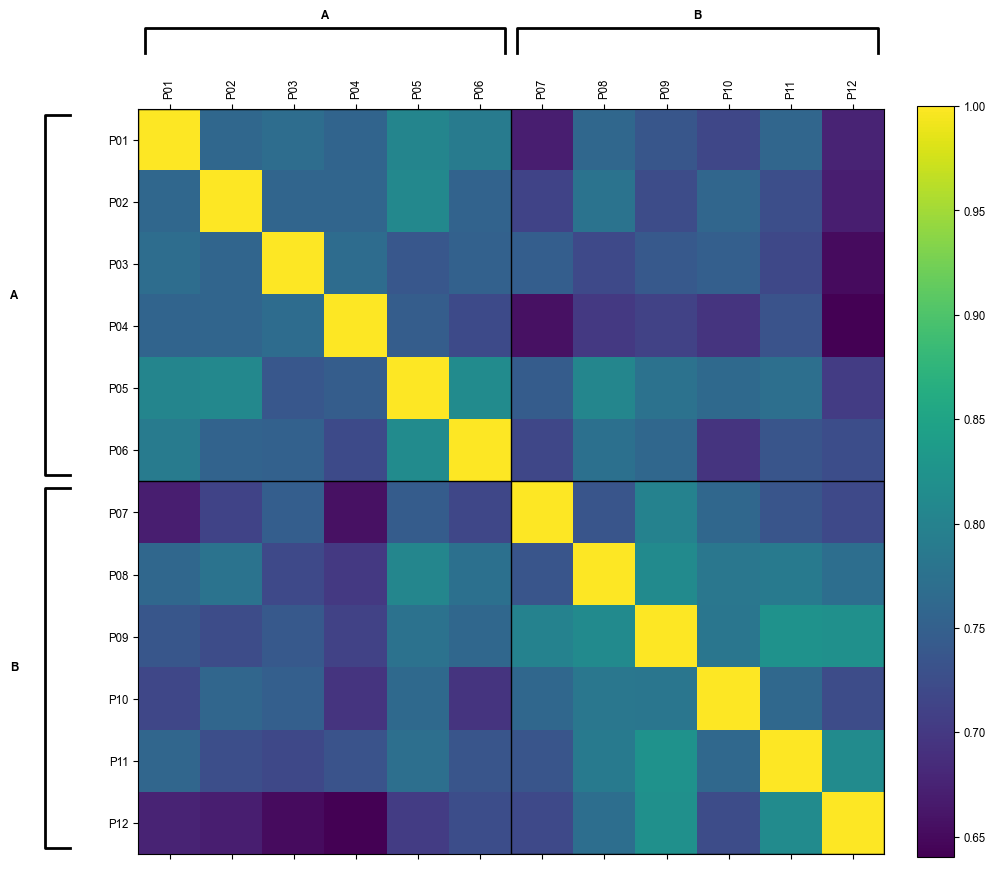

subject_b,P01,P02,P03,P04,P05,P06,P07,P08,P09,P10,P11,P12
subject_a,,,,,,,,,,,,
P01,1.000000,0.760490,0.768623,0.756689,0.804173,0.789763,0.670687,0.759968,0.736131,0.717451,0.759609,0.676586
P02,0.760490,1.000000,0.758350,0.757409,0.808573,0.754998,0.712181,0.777491,0.724647,0.758701,0.726675,0.670536
P03,0.768623,0.758350,1.000000,0.767617,0.738602,0.751979,0.748321,0.720160,0.740313,0.749788,0.717735,0.651446
P04,0.756689,0.757409,0.767617,1.000000,0.746956,0.721232,0.657008,0.700318,0.711446,0.694012,0.732312,0.640447
P05,0.804173,0.808573,0.738602,0.746956,1.000000,0.813828,0.745591,0.804986,0.775699,0.763183,0.771978,0.703924
P06,0.789763,0.754998,0.751979,0.721232,0.813828,1.000000,0.717503,0.773603,0.760029,0.694587,0.735483,0.725321
P07,0.670687,0.712181,0.748321,0.657008,0.745591,0.717503,1.000000,0.735323,0.800012,0.760777,0.735860,0.719296
P08,0.759968,0.777491,0.720160,0.700318,0.804986,0.773603,0.735323,1.000000,0.812366,0.783563,0.787776,0.769880
P09,0.736131,0.724647,0.740313,0.711446,0.775699,0.760029,0.800012,0.812366,1.000000,0.781930,0.823368,0.820438


In [6]:
subjects = res.subjects
grouping = {subj: ('A' if i < len(subjects) // 2 else 'B') for i, subj in enumerate(subjects)}
res.matshow(which='s_dir', grouping=grouping)

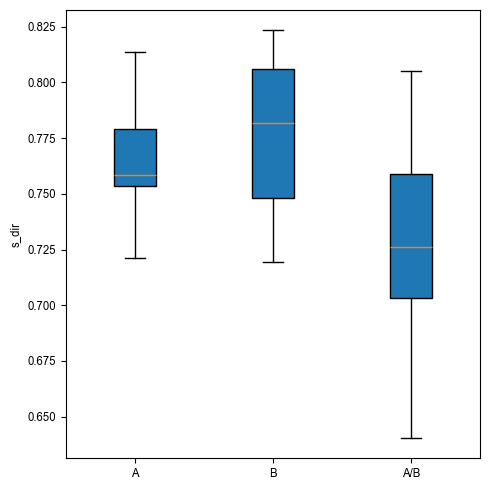

In [7]:
res.show_boxplot(grouping, which='s_dir')  # within-group vs. between-group similarity

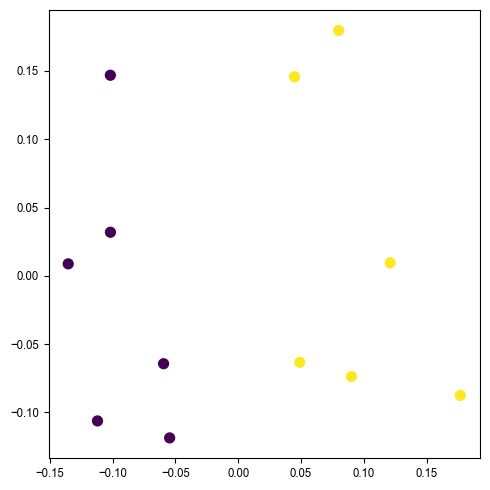

In [8]:
res.show_multidimensional_scaling(grouping=grouping, which='s_dir')

## Permutation test
Are subjects more similar *within* their group than *between* groups?
Statistic: `mean(within) - mean(between)`; group labels are shuffled under the null
(one-sided, `(r + 1) / (n + 1)` p-value). For the arbitrary split above, expect p ≈ chance.

In [9]:
res.permutation_test(grouping, which='s_dir')

Permutation test: 100%|██████████| 10000/10000 [00:00<00:00, 130189.56it/s]


{'which': 's_dir',
 'within_mean': 0.7710105149824574,
 'between_mean': 0.7257182980554391,
 'observed': 0.04529221692701835,
 'p_value': 0.0027997200279972004,
 'n_permutations': 10000}

## Similarity over time
Sliding-window profile: pairwise similarities recomputed per time window → how synchronous
are the viewers as the trial goes on? Defaults: `window` = a third of the viewing
time, 50% overlap; subjects with fewer than `min_saccades` saccades in a window sit that
window out. With a `grouping`, one curve per group (within) and per group pair (between).

Sliding-window similarity: 100%|██████████| 5/5 [00:04<00:00,  1.04it/s]


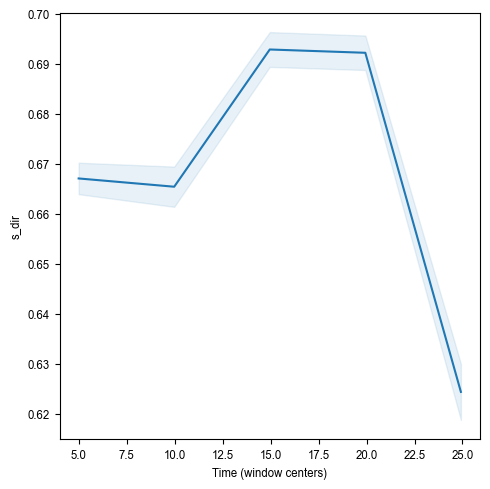

{'all pairs':               mean       std
 t_center                    
 4.98355   0.667047  0.062892
 9.96710   0.665395  0.080493
 14.95065  0.692824  0.069546
 19.93420  0.692165  0.068959
 24.91775  0.624385  0.112009}

In [10]:
profile = ds.compute_heatmatch_similarity_profile(sigma=50, density_coherence_tradeoff=0.5)
profile.show_profile(which='s_dir')  # viewer synchrony typically decreases over the trial

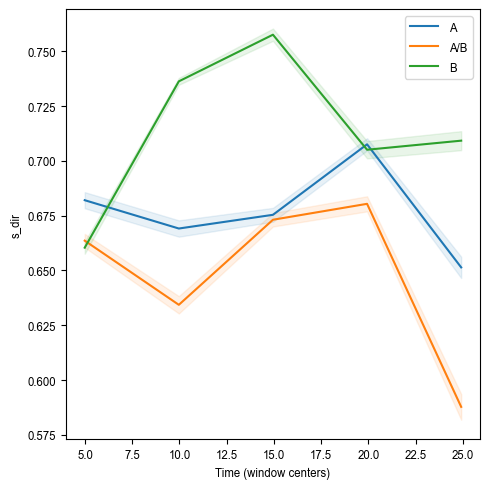

{'A':               mean       std
 t_center                    
 4.98355   0.682042  0.073445
 9.96710   0.669121  0.074571
 14.95065  0.675375  0.063241
 19.93420  0.707538  0.055916
 24.91775  0.651385  0.097212,
 'A/B':               mean       std
 t_center                    
 4.98355   0.663577  0.061917
 9.96710   0.634313  0.079126
 14.95065  0.673125  0.061668
 19.93420  0.680385  0.068971
 24.91775  0.587749  0.117593,
 'B':               mean       std
 t_center                    
 4.98355   0.660381  0.055374
 9.96710   0.736268  0.031423
 14.95065  0.757550  0.056003
 19.93420  0.705065  0.079189
 24.91775  0.709203  0.086763}

In [11]:
profile.show_profile(which='s_dir', grouping=grouping)

Compare with `which='s_loc'` to separate *where* subjects look from *in which direction* they saccade.